In [9]:
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

from src import preprocessing, utils

np.set_printoptions(precision=1, suppress=True)

In [10]:
image = np.array([
    [100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100],
    [100, 100,  10,  10,  10],
    [100, 100,  10,  10,  10],
    [100, 100,  10,  10,  10],
], dtype=float)
image

array([[100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100.],
       [100., 100.,  10.,  10.,  10.],
       [100., 100.,  10.,  10.,  10.],
       [100., 100.,  10.,  10.,  10.]])

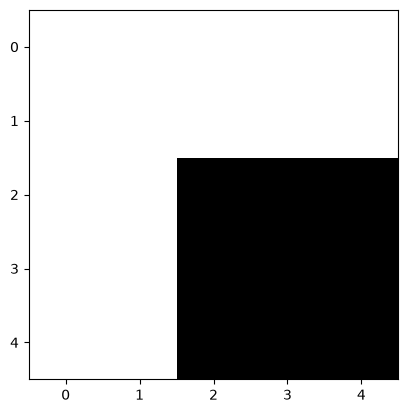

In [11]:
plt.figure()
plt.imshow(image, cmap='gray')

In [14]:
# Box blur kernel of size 3x3
kernel = np.ones((3,3)) / 9
print(kernel)
print("sum of weights of the box blur kernel: ", kernel.sum())

[[0.1 0.1 0.1]
 [0.1 0.1 0.1]
 [0.1 0.1 0.1]]
sum of weights of the box blur kernel:  1.0


In [13]:
#top left corner of the window
row, col = 1,1
patch = image[row:row+3, col:col+3]    # the 9 pixels under the window
products = patch * kernel            # cell by cell multiplication
total = products.sum()
print(patch)
print(products)
print(total)

[[100. 100. 100.]
 [100.  10.  10.]
 [100.  10.  10.]]
[[11.1 11.1 11.1]
 [11.1  1.1  1.1]
 [11.1  1.1  1.1]]
60.0


In [15]:
def conv_step(image, kernel, row, col):
    """ one window: patch -> products -> sum"""
    k = kernel.shape[0]
    patch = image[row:row+k, col:col+k]
    products = patch * kernel
    return patch, products, products.sum()

# position of the window (0,0)
conv_step(image, kernel, 0, 0)

(array([[100., 100., 100.],
        [100., 100., 100.],
        [100., 100.,  10.]]),
 array([[11.1, 11.1, 11.1],
        [11.1, 11.1, 11.1],
        [11.1, 11.1,  1.1]]),
 np.float64(90.0))

In [17]:
# SLIDING THE KERNEL
# 5x5 input image
# 3x3 kernel
# NO padding
# Stride of 1
# -> 3x3

n_out = image.shape[0] - kernel.shape[0] + 1
out = np.zeros((n_out, n_out))

for r in range(n_out):
    for c in range(n_out):
        _, _, out[r,c] = conv_step(image, kernel, r, c)
        print(f"window at position {r}, {c} -> {out[r,c]}")

out


window at position 0, 0 -> 90.0
window at position 0, 1 -> 80.0
window at position 0, 2 -> 70.0
window at position 1, 0 -> 80.0
window at position 1, 1 -> 60.0
window at position 1, 2 -> 40.0
window at position 2, 0 -> 70.0
window at position 2, 1 -> 40.0
window at position 2, 2 -> 10.0


array([[90., 80., 70.],
       [80., 60., 40.],
       [70., 40., 10.]])

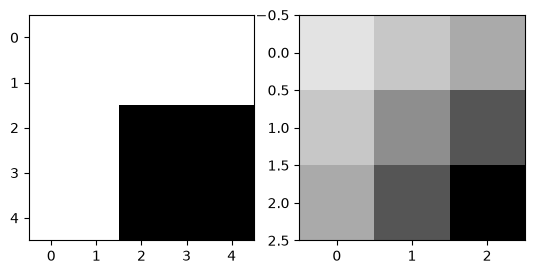

In [18]:
plt.subplot(1,2,1)
plt.imshow(image, 'gray', vmin=10, vmax=100)
plt.subplot(1,2,2)
plt.imshow(out, cmap='gray', vmin=10, vmax=100)

Padding and stride

In [20]:
def output_size(n, k, padding=0, stride=1):
    return (n + 2*padding - k) // stride + 1

# input 5x5; k 3x3, padding 0, stride 2
print(output_size(5, 3, 0, 2))

2


conv2d

In [21]:
def conv2d(image, kernel, padding, stride, pad_mode="constant"):
    k = kernel.shape[0]
    padded = np.pad(image, padding, mode=pad_mode)
    out_h = output_size(image.shape[0], k, padding, stride)
    out_w = output_size(image.shape[1], k, padding, stride)
    out = np.zeros((out_h, out_w))
    for r in range(out_h):
        for c in range(out_w):
            _, _, out[r,c] = conv_step(padded, kernel, r*stride, c*stride)
    return out

conv2d(image, kernel, padding=0, stride=1)

array([[90., 80., 70.],
       [80., 60., 40.],
       [70., 40., 10.]])

In [22]:
conv2d(image, kernel, padding=0, stride=2)

array([[90., 70.],
       [70., 10.]])

Different kernels

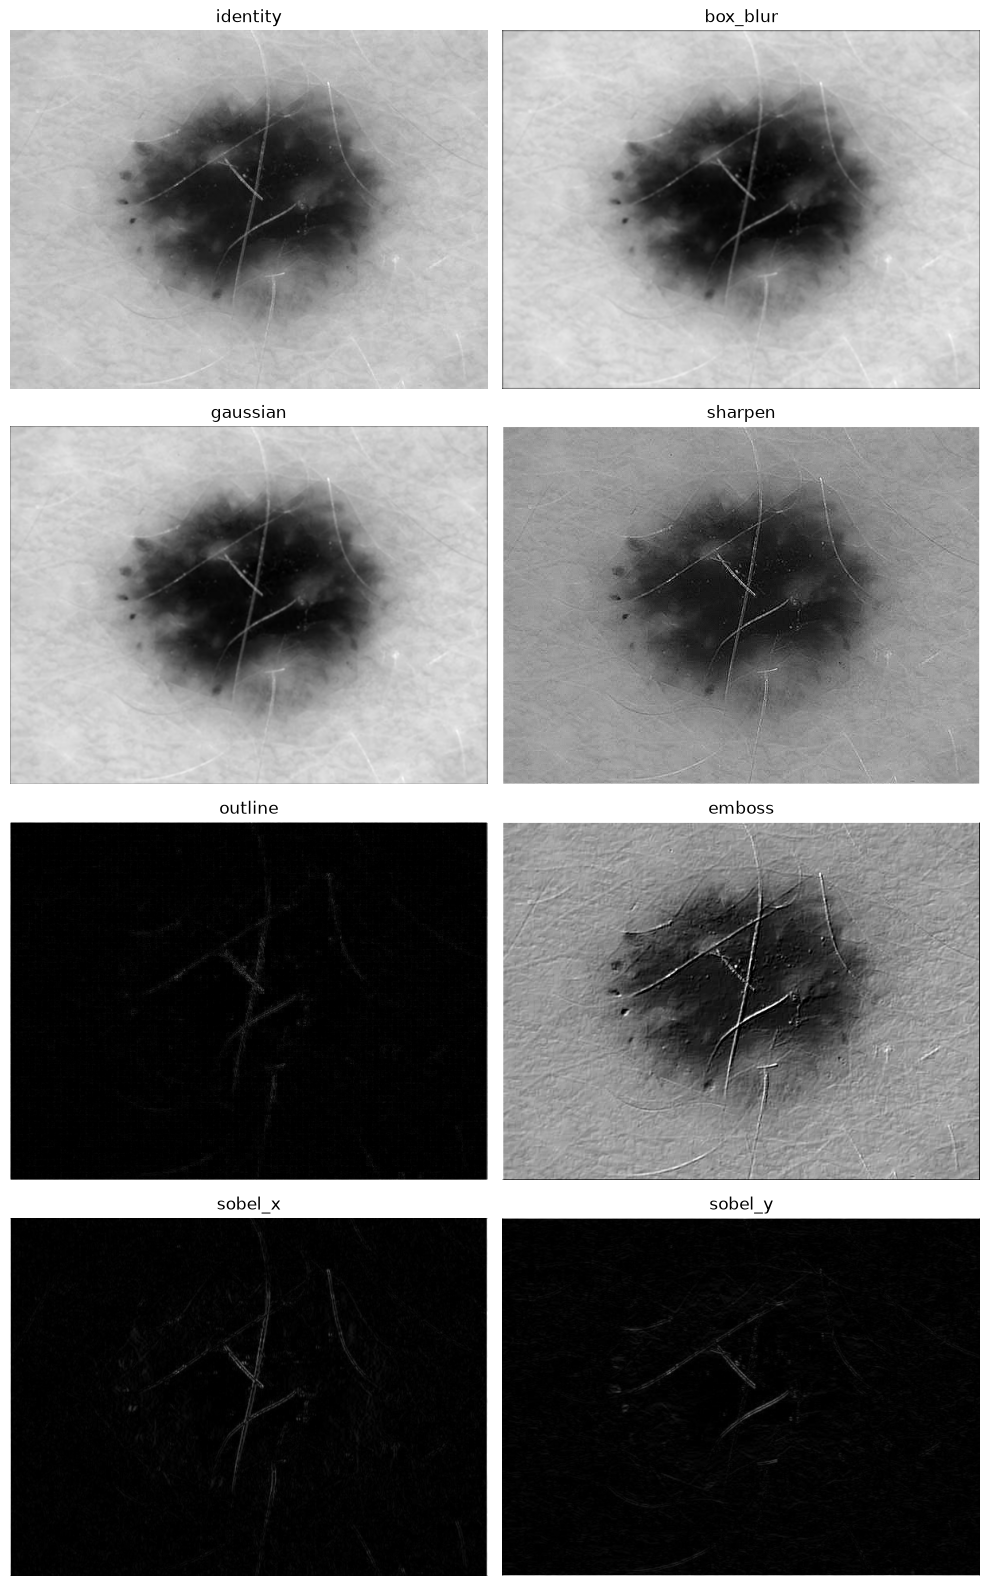

In [33]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the target image using the relative path from the notebooks directory
img_path = "../data/milk10k/images/ISIC_0073863.jpg"
image_raw = Image.open(img_path).convert("L")  # Convert directly to 2D grayscale
image = np.array(image_raw, dtype=np.float32)

# 2. Define all required kernels
KERNELS = {
    "identity": np.array([
        [0, 0, 0],
        [0, 1, 0],
        [0, 0, 0]
    ]),
    "box_blur": np.ones((3, 3)) / 9,
    "gaussian": np.array([
        [1, 2, 1],
        [2, 4, 2],
        [1, 2, 1]
    ]) / 16,
    "sharpen": np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ]),
    "outline": np.array([
        [-1, -1, -1],
        [-1,  8, -1],
        [-1, -1, -1]
    ]),
    "emboss": np.array([
        [-2, -1,  0],
        [-1,  1,  1],
        [ 0,  1,  2]
    ]),
    "sobel_x": np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ]),
    "sobel_y": np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ])
}

# 3. Apply kernels and plot in a 4 rows x 2 columns grid
plt.figure(figsize=(10, 16))

for i, (name, kernel) in enumerate(KERNELS.items()):
    out = conv2d(image, kernel, padding=1, stride=1)
    
    # Use absolute values for edge detectors to prevent negative clipping
    if "sobel" in name or name == "outline":
        out_display = np.abs(out)
    else:
        out_display = np.clip(out, 0, 255)

    plt.subplot(4, 2, i + 1)
    plt.imshow(out_display, cmap='gray')
    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
def fast_conv2d(image, kernel):
    """Same as conv2d(..., padding=1, pad_mode="symmetric") but in optimized C."""
    return ndimage.correlate(image, kernel, mode="reflect")

In [ ]:
t0 = time.perf_counter()
slow = conv2d(image, KERNELS["box_blur"], padding=1, pad_mode="symmetric")
t_slow = time.perf_counter() - t0
t0 = time.perf_counter()
fast = fast_conv2d(image, KERNELS["box_blur"])
t_fast = time.perf_counter() - t0
print(f"loops {t_slow:.3f}s | scipy {t_fast:.4f}s | {t_slow / t_fast:.0f}x faster")
print("same result:", np.allclose(slow, fast))